In [4]:
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD

OUTPUT = Path('/content/milestone3_outputs') if Path('/content').exists() else Path('milestone3_outputs')
OUTPUT.mkdir(exist_ok=True)
DATA = Path('/content/CFPB_Cleaned_Data (1).csv') if Path('/content').exists() else Path('CFPB_Cleaned_Data (1).csv')
if not DATA.exists():
    try:
        from google.colab import files
        print('Upload the cleaned Milestone 2 CSV now:')
        uploaded = files.upload()
        if 'CFPB_Cleaned_Data (1).csv' not in uploaded:
            DATA = Path('/content') / next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError(f'Put your cleaned CSV beside this notebook: {DATA}')
assert DATA.exists(), f'File not found: {DATA}'
print('Dataset:', DATA.name, '| Output folder:', OUTPUT)

Dataset: CFPB_Cleaned_Data (1).csv | Output folder: /content/milestone3_outputs


## 2. Dataset validation and overview


In [5]:
required = ['Complaint ID', 'Issue', 'Sub-issue', 'cleaned_text']
df = pd.read_csv(
    "/content/CFPB_Cleaned_Data (1).csv",
    usecols=["Complaint ID", "Issue", "Sub-issue", "cleaned_text"],
    low_memory=False
)
missing = set(required) - set(df.columns)
if missing: raise ValueError(f'Missing required columns: {sorted(missing)}')
if df['Complaint ID'].isna().any() or df['Complaint ID'].duplicated().any():
    raise ValueError('Complaint IDs must be non-null and unique')
df['cleaned_text'] = df['cleaned_text'].fillna('').astype(str)
df['Issue'] = df['Issue'].fillna('Unknown').astype(str)
if df['cleaned_text'].str.strip().eq('').any():
    raise ValueError('Some cleaned text values are empty')
summary = pd.DataFrame({'Measurement':['Records','Unique cleaned descriptions','Issue classes','Missing Sub-issue values'],
                        'Value':[len(df), df.cleaned_text.nunique(),df.Issue.nunique(),df['Sub-issue'].isna().sum()]})
display(summary)
display(df.head(8))

,Measurement,Value
0,Records,93626
1,Unique cleaned descriptions,55
2,Issue classes,15
3,Missing Sub-issue values,98


,Complaint ID,Issue,Sub-issue,cleaned_text
0,23970492,Getting a credit card,Card opened without my consent or knowledge,get credit card card open without consent know...
1,24660085,Fees or interest,Charged too much interest,fee interest charge much interest
2,25014569,Problem with a purchase shown on your statement,Credit card company isn't resolving a dispute ...,problem purchase show statement credit card co...
3,24858656,Problem with a purchase shown on your statement,Card was charged for something you did not pur...,problem purchase show statement card charge so...
4,24815374,"Other features, terms, or problems",Problem with balance transfer,feature term problem problem balance transfer
5,25161325,Fees or interest,Charged too much interest,fee interest charge much interest
6,25121714,Problem with a purchase shown on your statement,Overcharged for something you did purchase wit...,problem purchase show statement overcharge som...
7,25437697,Fees or interest,Charged too much interest,fee interest charge much interest


## 3. TF-IDF text representation


Training rows: 74900 | Test rows: 18726 | TF-IDF features: 365


,Term,Mean TF-IDF
0,purchase,0.109676
1,statement,0.102142
2,problem,0.101498
3,card,0.091865
4,credit,0.072702
5,credit card,0.071954
6,company,0.065789
7,purchase show,0.065080
8,show,0.065080
9,show statement,0.065080


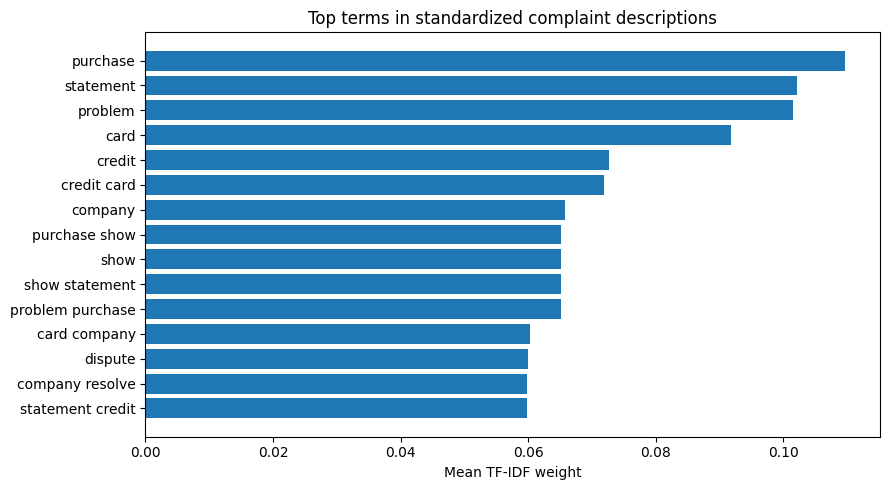

In [6]:
indices = np.arange(len(df))
train_idx, test_idx = train_test_split(indices, test_size=0.2, random_state=42, stratify=df['Issue'])
vectorizer = TfidfVectorizer(ngram_range=(1,2), min_df=2, max_features=3000, sublinear_tf=True)
X_train = vectorizer.fit_transform(df.iloc[train_idx].cleaned_text)
X_test = vectorizer.transform(df.iloc[test_idx].cleaned_text)
y_train = df.iloc[train_idx]['Issue']; y_test = df.iloc[test_idx]['Issue']
print('Training rows:', len(train_idx), '| Test rows:', len(test_idx), '| TF-IDF features:', X_train.shape[1])
feature_names = vectorizer.get_feature_names_out()
mean_weights = np.asarray(X_train.mean(axis=0)).ravel()
top = np.argsort(mean_weights)[-15:][::-1]
tfidf_table = pd.DataFrame({'Term':feature_names[top], 'Mean TF-IDF':mean_weights[top]})
display(tfidf_table)
fig, ax = plt.subplots(figsize=(9,5))
ax.barh(tfidf_table['Term'][::-1], tfidf_table['Mean TF-IDF'][::-1]); ax.set_xlabel('Mean TF-IDF weight'); ax.set_title('Top terms in standardized complaint descriptions')
plt.tight_layout(); fig.savefig(OUTPUT/'tfidf_terms.png', dpi=160); plt.show()

## 4. Supervised learning: Logistic Regression and Naive Bayes

,Model,Accuracy,Macro F1
0,Logistic Regression,1.000,1.000
1,Multinomial Naive Bayes,1.000,1.000
2,Majority-class baseline,0.325,0.033


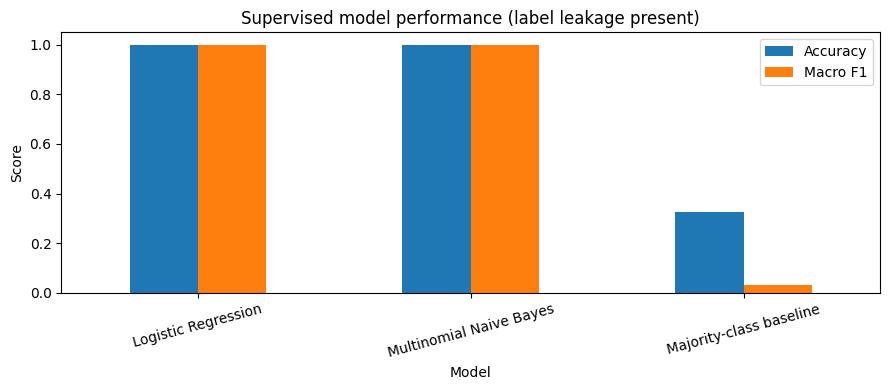

In [7]:
models = {'Logistic Regression':LogisticRegression(max_iter=500,random_state=42), 'Multinomial Naive Bayes':MultinomialNB()}
results = []; predictions = {}
majority = y_train.value_counts().idxmax()
for name, model in models.items():
    model.fit(X_train,y_train)
    p = model.predict(X_test)
    predictions[name] = p
    results.append({'Model':name,'Accuracy':accuracy_score(y_test,p),'Macro F1':f1_score(y_test,p,average='macro',zero_division=0)})
base_pred = np.repeat(majority,len(y_test))
results.append({'Model':'Majority-class baseline','Accuracy':accuracy_score(y_test,base_pred),'Macro F1':f1_score(y_test,base_pred,average='macro',zero_division=0)})
model_results = pd.DataFrame(results)
display(model_results.style.format({'Accuracy':'{:.3f}','Macro F1':'{:.3f}'}))
model_results.to_csv(OUTPUT/'model_comparison.csv',index=False)
fig,ax=plt.subplots(figsize=(9,4)); model_results.set_index('Model')[['Accuracy','Macro F1']].plot.bar(ax=ax,rot=15)
ax.set_ylim(0,1.05);ax.set_ylabel('Score');ax.set_title('Supervised model performance (label leakage present)')
plt.tight_layout();fig.savefig(OUTPUT/'model_comparison.png',dpi=160);plt.show()

## 5. Confusion matrix and classification details

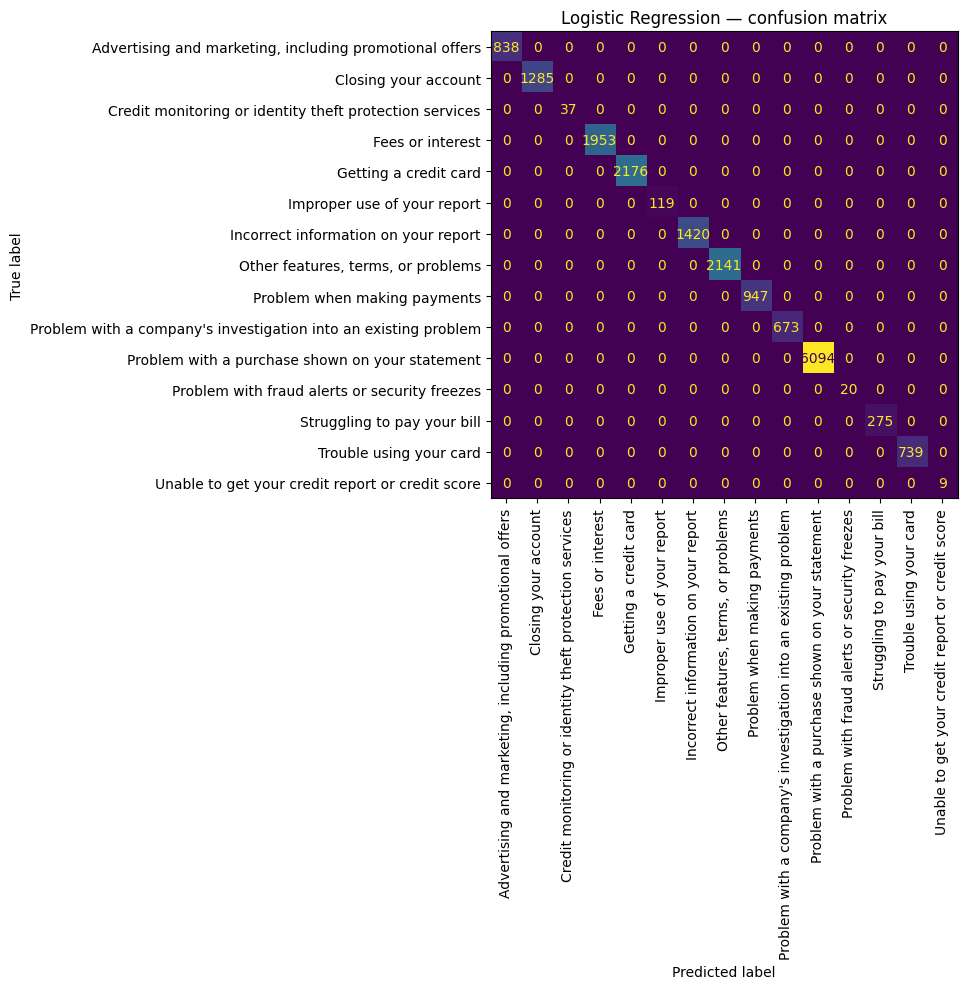

,precision,recall,f1-score,support
"Advertising and marketing, including promotional offers",1.0,1.0,1.0,838.0
Closing your account,1.0,1.0,1.0,1285.0
Credit monitoring or identity theft protection services,1.0,1.0,1.0,37.0
Fees or interest,1.0,1.0,1.0,1953.0
Getting a credit card,1.0,1.0,1.0,2176.0
Improper use of your report,1.0,1.0,1.0,119.0
Incorrect information on your report,1.0,1.0,1.0,1420.0
"Other features, terms, or problems",1.0,1.0,1.0,2141.0
Problem when making payments,1.0,1.0,1.0,947.0
Problem with a company's investigation into an existing problem,1.0,1.0,1.0,673.0


In [8]:
chosen = 'Logistic Regression'
labels = sorted(y_test.unique())
cm = confusion_matrix(y_test,predictions[chosen],labels=labels)
fig,ax=plt.subplots(figsize=(12,10)); ConfusionMatrixDisplay(cm,display_labels=labels).plot(ax=ax,xticks_rotation=90,values_format='d',colorbar=False)
ax.set_title('Logistic Regression — confusion matrix')
plt.tight_layout();fig.savefig(OUTPUT/'confusion_matrix.png',dpi=160);plt.show()
report = pd.DataFrame(classification_report(y_test,predictions[chosen],output_dict=True,zero_division=0)).T
report.to_csv(OUTPUT/'classification_report.csv')
display(report.round(3))

## 6. Unsupervised learning: K-Means clustering

,Cluster,Unique descriptions,Complaint records,Top terms
0,0,3,1373,"struggle, struggle pay, pay bill, pay, bill, file"
1,1,9,10704,"problem, term problem, feature term, feature, ..."
2,2,7,7102,"information, incorrect, incorrect information,..."
3,3,5,184,"service, theft protection, monitoring, credit ..."
4,4,15,53082,"card, purchase, credit card, get, credit, get ..."
5,5,2,6425,"close, close account, account, account close, ..."
6,6,9,14114,"problem, investigation, exist, investigation e..."
7,7,5,642,"report, use report, use, improper use, imprope..."


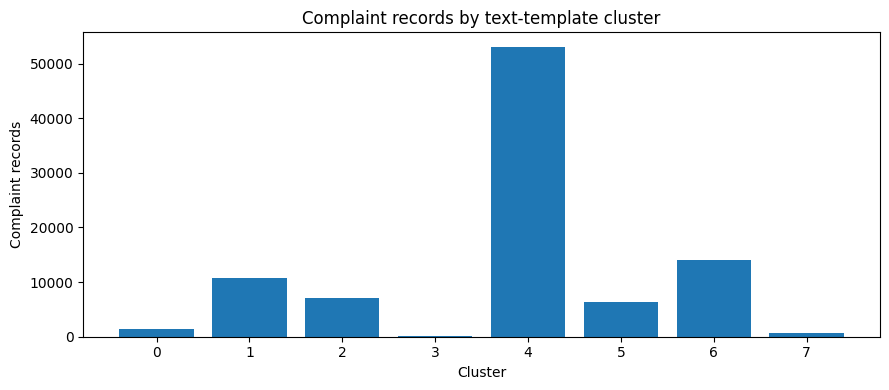

In [9]:
unique = df[['cleaned_text','Issue']].drop_duplicates('cleaned_text').reset_index(drop=True)
uv = TfidfVectorizer(ngram_range=(1,2))
UX = uv.fit_transform(unique.cleaned_text)
k = 8
km = KMeans(n_clusters=k,random_state=42,n_init=10)
unique['cluster'] = km.fit_predict(UX)
cluster_lookup = dict(zip(unique.cleaned_text,unique.cluster))
df['tfidf_cluster'] = df.cleaned_text.map(cluster_lookup)
terms = uv.get_feature_names_out()
cluster_descriptions = []
for i in range(k):
    top_terms = [terms[j] for j in np.argsort(km.cluster_centers_[i])[-6:][::-1]]
    cluster_descriptions.append({'Cluster':i,'Unique descriptions':int((unique.cluster==i).sum()),'Complaint records':int((df.tfidf_cluster==i).sum()),'Top terms':', '.join(top_terms)})
clusters = pd.DataFrame(cluster_descriptions)
display(clusters)
clusters.to_csv(OUTPUT/'cluster_summary.csv',index=False)
unique.to_csv(OUTPUT/'unique_text_clusters.csv',index=False)
fig,ax=plt.subplots(figsize=(9,4));ax.bar(clusters.Cluster.astype(str),clusters['Complaint records']);ax.set_xlabel('Cluster');ax.set_ylabel('Complaint records');ax.set_title('Complaint records by text-template cluster')
plt.tight_layout();fig.savefig(OUTPUT/'cluster_sizes.png',dpi=160);plt.show()

## 7. Two-dimensional cluster visualization
Truncated SVD projects the sparse TF-IDF features of the 55 unique templates into two dimensions.

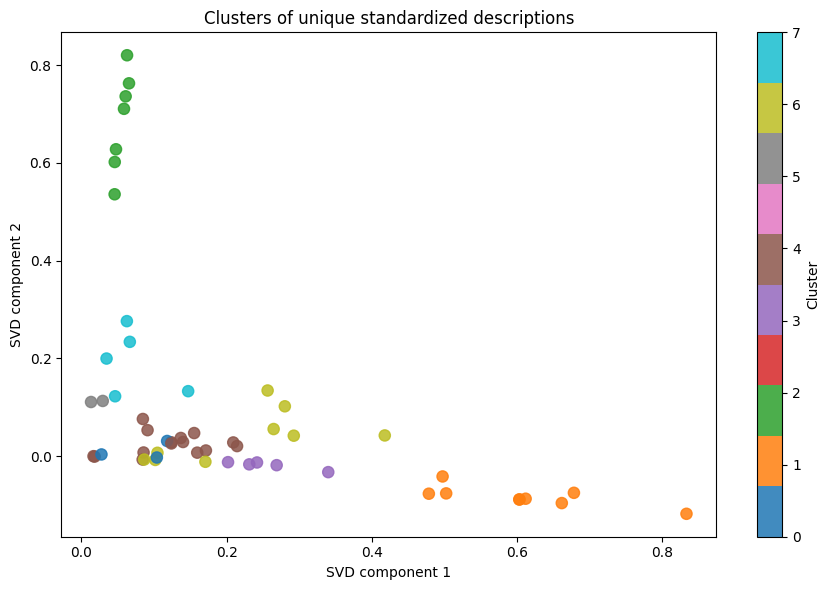

Explained variance (two components): 0.103


In [10]:
svd=TruncatedSVD(n_components=2,random_state=42)
coords=svd.fit_transform(UX)
fig,ax=plt.subplots(figsize=(9,6))
scatter=ax.scatter(coords[:,0],coords[:,1],c=unique.cluster,cmap='tab10',s=65,alpha=.85)
ax.set_xlabel('SVD component 1');ax.set_ylabel('SVD component 2');ax.set_title('Clusters of unique standardized descriptions')
fig.colorbar(scatter,ax=ax,label='Cluster');plt.tight_layout();fig.savefig(OUTPUT/'cluster_projection.png',dpi=160);plt.show()
print('Explained variance (two components):',round(float(svd.explained_variance_ratio_.sum()),3))

## 8. Streaming-data impact on this static dataset
The cleaned CSV does not contain complaint arrival dates, so it cannot support a verified monthly volume or drift chart on its own. A real streaming pipeline would ingest timestamped complaints, track changes in category proportions and vocabulary, monitor performance, and retrain when needed.

Potential effects: New complaint types may introduce vocabulary absent from the fitted TF-IDF model; category frequencies may shift; consumer narratives would provide richer context but require privacy and redaction controls; concept drift can reduce predictive performance. Repeatedly refitting TF-IDF changes feature weights and requires coordinated model versioning.

In [11]:
streaming_considerations = pd.DataFrame([
    ('New vocabulary','Previously unseen terms may be ignored by a fixed TF-IDF vocabulary','Track out-of-vocabulary rate; periodically refit and version models'),
    ('Changing complaint mix','Class frequencies and baseline accuracy can change','Compare rolling class proportions with training reference'),
    ('Model drift','Accuracy on future genuinely new texts may decline','Evaluate against newly labeled, held-out complaints'),
    ('Privacy','Narratives may contain sensitive consumer information','Redact and restrict access before analysis'),
    ('Latency','Incoming records require prompt processing','Use queued ingestion, validation, and batch or incremental scoring')],
    columns=['Streaming consideration','Impact','Recommended control'])
display(streaming_considerations)

,Streaming consideration,Impact,Recommended control
0,New vocabulary,Previously unseen terms may be ignored by a fi...,Track out-of-vocabulary rate; periodically ref...
1,Changing complaint mix,Class frequencies and baseline accuracy can ch...,Compare rolling class proportions with trainin...
2,Model drift,Accuracy on future genuinely new texts may dec...,"Evaluate against newly labeled, held-out compl..."
3,Privacy,Narratives may contain sensitive consumer info...,Redact and restrict access before analysis
4,Latency,Incoming records require prompt processing,"Use queued ingestion, validation, and batch or..."


## 9. Export the resulting data and supporting files
This cell saves a CSV of the cleaned input records with assigned clusters and holdout predictions. Predictions are populated only for the test partition. All outputs are saved in `milestone3_outputs`.

In [12]:
df['data_split']='train';df.loc[test_idx,'data_split']='test'
df['predicted_issue_holdout']='';df.loc[test_idx,'predicted_issue_holdout']=predictions['Logistic Regression']
result_cols=['Complaint ID','Issue','Sub-issue','cleaned_text','tfidf_cluster','data_split','predicted_issue_holdout']
df[result_cols].to_csv(OUTPUT/'Milestone3_Resulting_Data.csv',index=False)
display(df[result_cols].head(10))
print('Files created:')
for path in sorted(OUTPUT.iterdir()):print(' -',path.name)
# Optional download of all outputs from Google Colab
import shutil
zip_path=shutil.make_archive(str(OUTPUT),'zip',root_dir=OUTPUT)
print('ZIP:',zip_path)

,Complaint ID,Issue,Sub-issue,cleaned_text,tfidf_cluster,data_split,predicted_issue_holdout
0,23970492,Getting a credit card,Card opened without my consent or knowledge,get credit card card open without consent know...,4,train,
1,24660085,Fees or interest,Charged too much interest,fee interest charge much interest,4,train,
2,25014569,Problem with a purchase shown on your statement,Credit card company isn't resolving a dispute ...,problem purchase show statement credit card co...,4,train,
3,24858656,Problem with a purchase shown on your statement,Card was charged for something you did not pur...,problem purchase show statement card charge so...,4,train,
4,24815374,"Other features, terms, or problems",Problem with balance transfer,feature term problem problem balance transfer,1,train,
5,25161325,Fees or interest,Charged too much interest,fee interest charge much interest,4,train,
6,25121714,Problem with a purchase shown on your statement,Overcharged for something you did purchase wit...,problem purchase show statement overcharge som...,4,train,
7,25437697,Fees or interest,Charged too much interest,fee interest charge much interest,4,test,Fees or interest
8,25422922,Problem with a purchase shown on your statement,Credit card company isn't resolving a dispute ...,problem purchase show statement credit card co...,4,train,
9,25755734,Problem with a purchase shown on your statement,Credit card company isn't resolving a dispute ...,problem purchase show statement credit card co...,4,test,Problem with a purchase shown on your statement


Files created:
 - Milestone3_Resulting_Data.csv
 - classification_report.csv
 - cluster_projection.png
 - cluster_sizes.png
 - cluster_summary.csv
 - confusion_matrix.png
 - model_comparison.csv
 - model_comparison.png
 - tfidf_terms.png
 - unique_text_clusters.csv
ZIP: /content/milestone3_outputs.zip


## 10. Interpretation and limitations
- **TF-IDF:** A useful numerical representation of the standardized descriptions, but its top terms largely reflect existing category wording.
- **Supervised learning:** Logistic Regression and Naive Bayes can learn the existing Issue categories; high scores are inflated by target leakage and repetition.
- **Clustering:** Eight clusters summarize similarities between the 55 unique templates, not previously unknown consumer experiences.
- **Future work:** Incorporate properly sourced and de-identified archived consumer narratives, keep narrative text separate from prediction labels, and evaluate on genuinely unseen narratives. The original Milestone 2 dataset remains unchanged.
- **Streaming:** This cleaned file lacks timestamps. Temporal drift should be tested only when dated records are separately supplied and validated.

In [13]:
from google.colab import files
files.download('/content/milestone3_outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>